# Seven speech models against the official Supreme Court transcript

The Supreme Court publishes a certified reporter's transcript of every oral argument, and
the recording it was made from. So a machine transcript and a professional one of exactly
the same speech can be compared word for word.

Seven open speech recognition models were run over the 61 arguments of October Term 2017.
This notebook asks two things:

1. How close does each model get to the official record, depending on how you score it?
2. Do seven models together hear better than one - and where do they all fail?

Everything here reads small tables from `../findings/`. Nothing is transcribed in the
notebook; the pipeline that made the tables is described in `../pipeline/README.md`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

FINDINGS = Path("..") / "findings"
CROWD = FINDINGS / "crowd"

# The run each model's results come from (see findings/README.md).
RUNS = {
    "Whisper": "run-20260918-035220",
    "Qwen3": "run-20260921-051927",
    "Voxtral": "run-20260922-002324",
    "Canary": "run-20260921-033436",
    "Parakeet": "run-20260924-064733",
    "Granite": "run-20260923-011250",
    "Granite Plus": "run-20260924-164308",
}

## 1. The seven models, scored two ways

Each transcript is scored against the official one with **word error rate**: the share of
official words the model got wrong, left out, or added. The difference between the two
columns below is what gets thrown away before comparing:

- **benchmark rule** - punctuation, capitals, filler words and contractions are removed
  first. This is how published leaderboards score.
- **verbatim rule** - nothing is removed. This is closer to how a certified record is judged.

Both columns use the fixes added in October (`pipeline/scotus_asr/scoring/harmonise.py`),
which stop the scoring counting differences nobody could hear: "3553(e)" against "3553E",
"Vogt's" against "votes", "e-mails" against "emails". They took 0.4 to 0.6 points off every
model's benchmark score and changed no model's rank. The leaderboard version of the
benchmark rule, quirks included, is kept in the results file as `wer_standard`.

In [2]:
results = pd.read_csv(FINDINGS / "final-seven-model-results.csv")
table = results[["model", "parameters", "wer_standard_fixed", "wer_verbatim", "speed_x_realtime"]].copy()
table.columns = ["model", "size", "benchmark rule %", "verbatim rule %", "speed (x real time)"]
table["times worse"] = (table["verbatim rule %"] / table["benchmark rule %"]).round(1)
table.sort_values("benchmark rule %").reset_index(drop=True)

,model,size,benchmark rule %,verbatim rule %,speed (x real time),times worse
0,Qwen3-ASR-1.7B-hf,1.7B,4.442,15.549,4.59,3.5
1,whisper-large-v3,1.55B,5.711,14.527,18.18,2.5
2,Voxtral-Mini-3B-2507,4.7B,6.122,15.705,7.06,2.6
3,granite-speech-4.1-2b-plus,2.3B,6.417,29.051,1.57,4.5
4,canary-1b-v2,0.98B,6.683,16.124,35.27,2.4
5,parakeet-tdt-0.6b-v3,0.6B,6.938,18.181,47.04,2.6
6,granite-speech-4.1-2b,2.3B,7.841,17.214,7.86,2.2


Every model is **two to four and a half times worse** when scored as a record. Qwen3 wins
the benchmark rule by more than a point, but Whisper - the oldest model here, from 2023 -
produces the better record. A leaderboard would recommend the wrong model for this job.

Two cautions. Granite Plus cannot write punctuation or capitals at all (IBM removed them on
purpose), so its verbatim figure measures that decision, not its hearing. And the Qwen3
and Canary speeds were measured while the graphics card was short of memory, so they are
probably too low; the error rates are not affected.

## 2. Seven sets of ears

If several people listen to the same tape, the passages they all agree on are probably
right, and the passages where they disagree are the ones to replay. The same idea works
with models.

`tools/crowd.py` lines every model up against every word of the official transcript and
records whether each model got that word. This part uses the benchmark rule, because the
question is whether a model *heard* the word, not how it punctuated it.

In [3]:
heard = pd.read_csv(CROWD / "heard-by.csv")
heard["percent"] = (100 * heard["share"]).round(2)
total_words = heard["words"].sum()
print(f"{total_words:,} official words across 61 arguments")
heard[["heard_by", "words", "percent"]]

656,527 official words across 61 arguments


,heard_by,words,percent
0,0,10246,1.56
1,1,5503,0.84
2,2,7736,1.18
3,3,9603,1.46
4,4,7359,1.12
5,5,9968,1.52
6,6,33829,5.15
7,7,572283,87.17


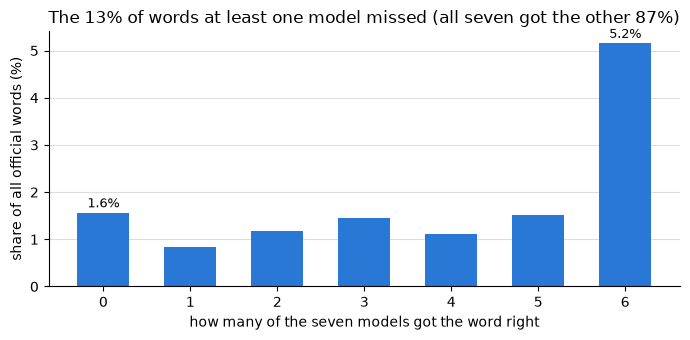

In [4]:
# All seven got 86.7% of the words. That bar would flatten the rest, so the chart
# shows only the words at least one model missed.
missed_by_some = heard[heard["heard_by"] < 7]
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(missed_by_some["heard_by"], missed_by_some["percent"], color="#2a78d6", width=0.6)
ax.set_xlabel("how many of the seven models got the word right")
ax.set_ylabel("share of all official words (%)")
ax.set_title("The 13% of words at least one model missed (all seven got the other 87%)")
ax.set_xticks(range(7))
ax.grid(axis="y", color="#dddddd", linewidth=0.8)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
for k in (0, 6):
    value = heard.loc[k, "percent"]
    ax.annotate(f"{value:.1f}%", (k, value), xytext=(0, 4), textcoords="offset points",
                ha="center", fontsize=9)
plt.tight_layout()
plt.show()

**87% of the words are heard by all seven models**, and most of the rest by six. At the
other end, **1.6% are heard by none of them**. That
1.6% is a floor - no way of combining these seven models can get those words back. The
best single model, Qwen3, misses 3.6% of the words on its own, so in principle a perfect
combination would more than halve its misses. The next question is whether an honest one can.

## 3. Does a vote beat the best model?

The vote must not look at the official transcript, or it would just be copying the answer.
So the models are lined up against each other instead: each model's words are aligned
against one "pivot" model, and at each position the word most models wrote wins. The
voted transcript is then scored like any other model.

The vote was built seven times, once with each model as the pivot, to check the answer
does not depend on that choice.

In [5]:
votes = pd.read_csv(CROWD / "models-and-vote.csv")
votes[["model", "wer_pct", "vote_with_this_pivot_wer_pct", "right_against_the_majority"]].rename(
    columns={
        "wer_pct": "model alone %",
        "vote_with_this_pivot_wer_pct": "vote, this pivot %",
        "right_against_the_majority": "words it alone (or nearly) got right",
    }
).sort_values("model alone %").reset_index(drop=True)

,model,model alone %,"vote, this pivot %",words it alone (or nearly) got right
0,Qwen3,4.464,5.007,13390
1,Whisper,5.726,5.278,5602
2,Voxtral,6.137,5.430,4165
3,Granite Plus,6.438,5.203,13132
4,Canary,6.698,5.451,2829
5,Parakeet,6.969,6.365,8587
6,Granite,7.863,6.286,2079


(These error rates pool every word in the 61 arguments, so they differ from the table in
section 1, which averages the 61 per-case rates, in the second decimal place.)

**The vote helps every model except the best one.** Whichever model is the pivot, the vote
lands between about 5.0% and 6.4% - better than most of the models alone, but never
as good as Qwen3's 4.5%. The last column starts to say why: Qwen3 and Granite Plus are each
right on over 13,000 words where most of the other models are wrong, more than twice as
many as Whisper. Splitting Qwen3's errors into kinds shows the rest:

In [6]:
qwen = votes.set_index("model").loc["Qwen3"]
pd.DataFrame({
    "Qwen3 alone": [qwen["substitutions"], qwen["deletions"], qwen["insertions"]],
    "vote, Qwen3 as pivot": [qwen["vote_substitutions"], qwen["vote_deletions"], qwen["vote_insertions"]],
}, index=["wrong word", "word left out", "word added"])

,Qwen3 alone,"vote, Qwen3 as pivot"
wrong word,7346.0,5284.0
word left out,16275.0,26308.0
word added,5685.0,1281.0


The vote fixes wrong words and added words, but it leaves out about 10,000 more words
than Qwen3 did. Those are words most models drop - a repeated word, a second speaker's
"I'm sorry" - and the minority that wrote them down gets outvoted. The wisdom of the crowd
only works when the members make *different* mistakes, and here the majority makes the
same one.

## 4. Do they make the same mistakes?

Hard words are hard for everyone, so any two models will miss some of the same words. The
useful question is how much more often than chance. The table below divides "how often
both miss a word" by what you would expect if the two missed words independently. 1 would
mean independent; bigger means more alike.

In [7]:
shared = pd.read_csv(CROWD / "shared-misses.csv", index_col=0)
miss_rate = votes.set_index("model")["missed_words_pct"] / 100
# P(both miss) / (P(row misses) * P(column misses)), which is the same both ways round
lift = shared.div(miss_rate, axis=1)
for m in lift.index:
    lift.loc[m, m] = float("nan")
pairs = lift.stack().dropna()
print("most alike:", pairs.idxmax(), round(pairs.max(), 1))
print("least alike:", pairs.idxmin(), round(pairs.min(), 1))
lift.round(1)

most alike: ('Voxtral', 'Whisper') 15.4
least alike: ('Parakeet', 'Granite') 8.0


,Whisper,Qwen3,Voxtral,Canary,Parakeet,Granite,Granite Plus
when_this_model_misses,,,,,,,
Whisper,NaN,13.3,15.4,12.5,9.6,11.1,9.5
Qwen3,13.3,NaN,13.1,12.3,12.1,10.7,15.2
Voxtral,15.4,13.1,NaN,12.2,9.4,11.0,9.5
Canary,12.5,12.3,12.2,NaN,9.3,10.1,9.7
Parakeet,9.6,12.1,9.4,9.3,NaN,8.0,9.9
Granite,11.1,10.8,11.0,10.1,8.1,NaN,9.3
Granite Plus,9.6,15.3,9.5,9.7,9.9,9.3,NaN


Even the least alike pair misses the same words about eight times as often as chance
would give, so the seven are far from independent listeners. The most alike pair is
Whisper and Voxtral, at about fifteen times, which fits how Voxtral is built: its audio
encoder comes from Whisper. Close behind are Qwen3 and Granite Plus, the two models that
leave out the fewest words. Seven models are fewer than seven independent sets of ears,
which is the other half of why the vote cannot beat Qwen3.

## 5. Where the hard words are

The official transcript marks one speaker cutting in on another with a dash. So it is
possible to check whether the words the models struggle with sit near an interruption.

In [8]:
dashes = pd.read_csv(CROWD / "interruptions.csv")
dashes["percent near a dash"] = (100 * dashes["share_near_a_dash"]).round(1)
names = {
    "easy": "4 or more models right",
    "split": "2 or 3 models right",
    "nobody": "0 or 1 models right",
    "against": "6+ models agree, record differs",
}
dashes["kind"] = dashes["kind"].map(names)
dashes[["kind", "words", "percent near a dash"]]

,kind,words,percent near a dash
0,4 or more models right,623439,8.8
1,"6+ models agree, record differs",11114,60.6
2,2 or 3 models right,17339,71.7
3,0 or 1 models right,4635,53.5


Ordinary words sit near an interruption about 9% of the time. The words the models split
over, or all miss, sit near one **more than half the time**. The hardest passages for the
machines are people talking over each other - the reporter in the room wrote down both
voices, and the models kept one.

## 6. When the models agree with each other and not with the record

These are the most interesting places for a court reporter: six or more models wrote the
same thing, and the official transcript says something else. Either the models share a
blind spot, or the record differs from what was said.

`tools/crowd.py` gives each spot two labels. **What happened** in the speech comes from
simple checks that all run on every spot - a change of speaker nearby, a repeated or
cut-off word, a name or legal term, a number, a short common word - with the main label
picked in that order. **What the machines did** counts how many of the seven matched the
record. Spots no check claims are "other", and a language model sorts those
(`tools/judge_spots.py`, below). The checks were written after reading 157 spots by hand
(`../flagged-spots-review.md`); how often they agree with labels made by ear is still to
be measured, so the counts below are a first sort, not a result.

In [9]:
against = pd.read_csv(CROWD / "against-the-record.csv")
against.groupby(["direction", "what_happened"]).size().rename("stretches").to_frame()

stretches
direction                               what_happened                       
machines agree, record does not have it disfluency                        16
                                        not a real difference             46
                                        number or citation                 3
                                        other                             37
                                        small word or ending             230
                                        speaker change or overlap         40
record has it, machines do not          disfluency                      1388
                                        name or legal term               383
                                        not a real difference              1
                                        number or citation                48
                                        other                            517
                                        small word or ending            1414
                                        speaker change or overlap       3794

The 554 "other" spots were given to a language model to sort: **Gemma 4 31B**, an open
model run on this laptop through Ollama, at temperature 0. It is mid-sized, not a frontier
model like Claude or GPT, and it reads only the text, never the audio. It is held to the
same terms as a person labelling by ear: the same nine kinds with the same descriptions, and
as many kinds as fit, each marked primary or secondary. It still tends to call a word swapped
for a sound-alike "left out or added", and it can't see two people talking at once from text.
Here is how it sorted them, counting a spot under each of its primary kinds:

In [10]:
judge = pd.read_csv(CROWD / "judge.csv", keep_default_na=False)
key = ["docket", "clock", "record", "machines_wrote"]
other = pd.read_csv(CROWD / "against-the-record.csv", keep_default_na=False)
other = other[other["what_happened"] == "other"].merge(judge, on=key)
several = ((other["judge_primary"].str.contains(";")) | (other["judge_secondary"] != "")).sum()
print(f"{several} of {len(other)} spots were given more than one kind")
kinds = other.assign(judge_kind=other["judge_primary"].str.split("; ")).explode("judge_kind")
kinds.groupby(["direction", "judge_kind"]).size().rename("stretches").to_frame()

246 of 554 spots were given more than one kind


stretches
direction                               judge_kind                          
machines agree, record does not have it disfluency                         1
                                        misheard word                      4
                                        name or legal term                 2
                                        not a real difference              2
                                        number or citation                 3
                                        words left out or added           25
record has it, machines do not          disfluency                        71
                                        misheard word                    145
                                        name or legal term                21
                                        not a real difference             32
                                        number or citation                 4
                                        small word or ending             112
                                        speaker change or overlap          1
                                        words left out or added          156

In [11]:
def examples(kind, n=8):
    rows = against[against["what_happened"] == kind]
    return rows[["docket", "clock", "record", "machines_wrote", "machines"]].sample(n, random_state=1)

examples("name or legal term")

,docket,clock,record,machines_wrote,machines
3823,16-424,0:51:52,Menna,mena,most agree on something else
7691,17-586,1:09:24,"Gingles,",jingles,a few models have it
2692,16-1432,0:44:08,Melin's,mellons,all seven wrote the same other thing
3910,16-460,0:32:25,AEDPA,edpa,most agree on something else
6057,17-2,0:47:31,Microsoft's,microsoft,all seven wrote the same other thing
6978,17-432,0:27:35,tolled,told,a few models have it
340,15-1439,1:03:05,"preemptions,",preemption,all seven wrote the same other thing
2294,16-1348,0:35:05,McGUIRE:,NaN,all seven wrote the same other thing


In [12]:
examples("speaker change or overlap")

,docket,clock,record,machines_wrote,machines
4496,16-534,0:31:25,about.,NaN,a few models have it
31,15-1204_OT2017,0:22:57,I would,NaN,most agree on something else
5350,16-961,0:13:31,who's civil?,NaN,all seven wrote the same other thing
6483,17-333,0:01:05,Honor.,NaN,all seven wrote the same other thing
7246,17-494,0:51:55,"Yeah, I think",NaN,a few models have it
3364,16-285,0:08:38,Mr. Clement,NaN,all seven wrote the same other thing
3470,16-299,0:08:44,Right.,NaN,all seven wrote the same other thing
1200,16-111,0:51:33,can't turn,NaN,all seven wrote the same other thing


Reading through them, most are **not** the reporter getting it wrong:

- **A change of speaker** - "That's correct.", "I'm sorry." - said over the person who had
  the floor. This is the biggest group. The record has both voices; the machines kept the
  louder one.
- **Repeated words and restarts** the record keeps ("I - I think") and the models tidy away.
- **Names and legal terms** the models all mishear the same way: Printz written "prince",
  comity written "comedy", Cronic written "chronic". In 17-494 counsel cites "the Kavanagh
  report" and the models write "Kavanaugh", the spelling all over their training data.
  Agreement among machines is not evidence when they share a blind spot.
- **Writing conventions** going the other way: counsel says "quote" aloud and the reporter
  writes quotation marks.

Short common words - *a* against *the*, *could* against *can* - are the genuine
disagreements, where only listening can say who is right. Some of them may be places where
the official transcript was tidied.

## 7. What is left to listen to

Two lists come out of this, both with the case and the time in the recording:

- `findings/crowd/hard-passages.csv` - stretches of three or more words that at most three
  models got right.
- the silence check - stretches where a model wrote nothing but a speech detector heard
  speech, and the other models were silent there too.

In [13]:
hard = pd.read_csv(CROWD / "hard-passages.csv")
print(f"{len(hard)} hard passages; {hard['near_interruption'].mean():.0%} are next to an interruption")
hard.sort_values("words", ascending=False)[["docket", "clock", "words", "record", "Whisper", "Qwen3"]].head(8)

1587 hard passages; 81% are next to an interruption


,docket,clock,words,record,Whisper,Qwen3
1565,17-965,0:29:51,12,in - Okay. So you want me to consider - -- the...,in the law that actually,okay so you want me to consider
33,15-1439,0:17:38,11,affirmatively -- I'll go read that. I'll read ...,affirmatively,have fundamentally
500,16-1371,0:42:27,10,"wouldn't oppose - Yes, and -- and - -- his rig...",yes and,would not have closed the door yes and
417,16-1276,0:50:28,10,in -- in a properly - Let's get to the merits.,let us get to the merits,let us get to the merits
296,16-1144,0:14:18,10,because - -- experience -- I -- I was respondi...,am sorry i am sorry i am serious i mean,i mean
1195,17-130,0:30:58,10,hard - -- even though they have the same - It'...,even though they have the same it is hard,even though they have it is hard
703,16-299,0:23:16,9,that's a - You have -- do you have any,do you have any,you have many
809,16-476,0:30:55,9,Isn't it enough just to say it's,NaN,is not it enough just to say it is


In [14]:
silences = pd.concat(
    [pd.read_csv(FINDINGS / run / "triangulation.csv") for run in RUNS.values()]
)
flagged = silences[silences["needs_an_ear"]].sort_values(["docket", "start"])

# Several models can flag the same moment; count each moment once.
moments = []
for docket, group in flagged.groupby("docket"):
    end = -1.0
    for _, row in group.iterrows():
        if row["start"] > end:
            moments.append({"docket": docket, "clock": row["start_clock"], "seconds": row["seconds"],
                            "models silent": row["engines_silent"]})
        end = max(end, row["start"] + row["seconds"])
moments = pd.DataFrame(moments)
print(f"{len(moments)} moments where a model left out speech the others also missed, "
      f"{moments['seconds'].sum():.0f} seconds in all")
moments

12 moments where a model left out speech the others also missed, 52 seconds in all


,docket,clock,seconds,models silent
0,15-1509,0:21:57,3.32,7
1,16-1067,0:49:52,6.00,7
2,16-111,0:17:04,2.92,7
3,16-1362,0:51:44,9.32,7
4,16-498,0:47:19,4.16,7
5,16-9493,0:15:52,2.89,7
6,16-9493,0:53:01,4.40,7
7,16-980,0:01:10,3.60,7
8,17-2,0:34:39,4.84,7
9,17-387,0:29:40,3.52,7


## What this means

- Scored the way a record is judged, every model here is two to four and a half times worse
  than its benchmark score, and the benchmark ranking does not pick the best record.
- Seven models agree on 87% of the words. A vote among them helps the weaker models but
  does not beat the best one, because the models share many of the same mistakes.
- The places they fail together are mostly people talking over each other, where the
  reporter captured two voices and the machines one; repeated words the record keeps; and
  names and legal terms they all mishear the same way. Plain mishearing of clear speech is
  rare.
- Where all seven agree against the record, the record is usually right. The short-word
  disagreements that remain are a listening list, not a verdict.

**Limits.** The models are not independent: they share training data, and four of them
share one aligner for their timings. The sorting of flagged spots is checked by rules and a
mid-sized local language model (Gemma 4 31B), not yet by ear, so its counts are not ones to quote. And the official
transcript is marked "subject to final review", so it is the best available reference
rather than a perfect one. There is still no human baseline - how much two professional
transcripts of the same argument would differ.